In [1]:
get_ipython().run_line_magic('matplotlib', 'inline')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 

df = pd.read_csv('student_grade_ses_dataset.csv')

# Provide idea of the dataframe we are dealing with 
print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12025 entries, 0 to 12024
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  12025 non-null  object 
 1   academic_year               12025 non-null  object 
 2   survey_date                 12025 non-null  object 
 3   age                         12025 non-null  int64  
 4   gender                      12025 non-null  object 
 5   grade_level                 12025 non-null  int64  
 6   school_type                 12025 non-null  object 
 7   residence_type              12025 non-null  object 
 8   family_size                 12025 non-null  int64  
 9   num_siblings                12025 non-null  int64  
 10  single_parent_household     12025 non-null  int64  
 11  family_income_bracket       12025 non-null  object 
 12  annual_family_income_inr    11304 non-null  float64
 13  father_education_level      116

In [2]:
# Data Preprocessing 

# 1. Cleaning Duplicate Rows 
duplicates = df[df.duplicated()]
print("Duplicate Rows:")
print(duplicates)

row_count_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
row_count_after = len(df)
print(f"{row_count_before} rows -> {row_count_after} after removing duplicates")

# 2. Set 'student_id' as the index and drop it from the standard columns
is_all_unique = df['student_id'].is_unique
print(f"Column student_id uniqueness: {is_all_unique}")
df = df.set_index('student_id', drop=True)


Duplicate Rows:
      student_id academic_year survey_date  age  gender  grade_level  \
2052   STU100247     2024-2025     10/3/25   13    Male            8   
2323   STU111139     2023-2024      5/3/25   17  Female           12   
4406   STU107482     2022-2023      1/5/25   14   Other            9   
5645   STU110619     2023-2024      8/5/25   11    Male            7   
5715   STU104160     2022-2023     12/5/25   13  Female            8   
5801   STU108370     2022-2023     22/3/25   18    Male           12   
6089   STU100191     2022-2023      8/3/25   15  Female           10   
6099   STU108270     2021-2022     16/4/25   12    Male            8   
7395   STU111279     2024-2025     19/4/25   15  Female            9   
7700   STU101857     2021-2022     10/5/25   14  Female           10   
7788   STU108388     2021-2022     10/4/25   18  Female           12   
7902   STU104036     2022-2023      3/4/25   14  Female           10   
7990   STU105705     2023-2024      7/3/25   15 

## TODO: What to do about missing rows  

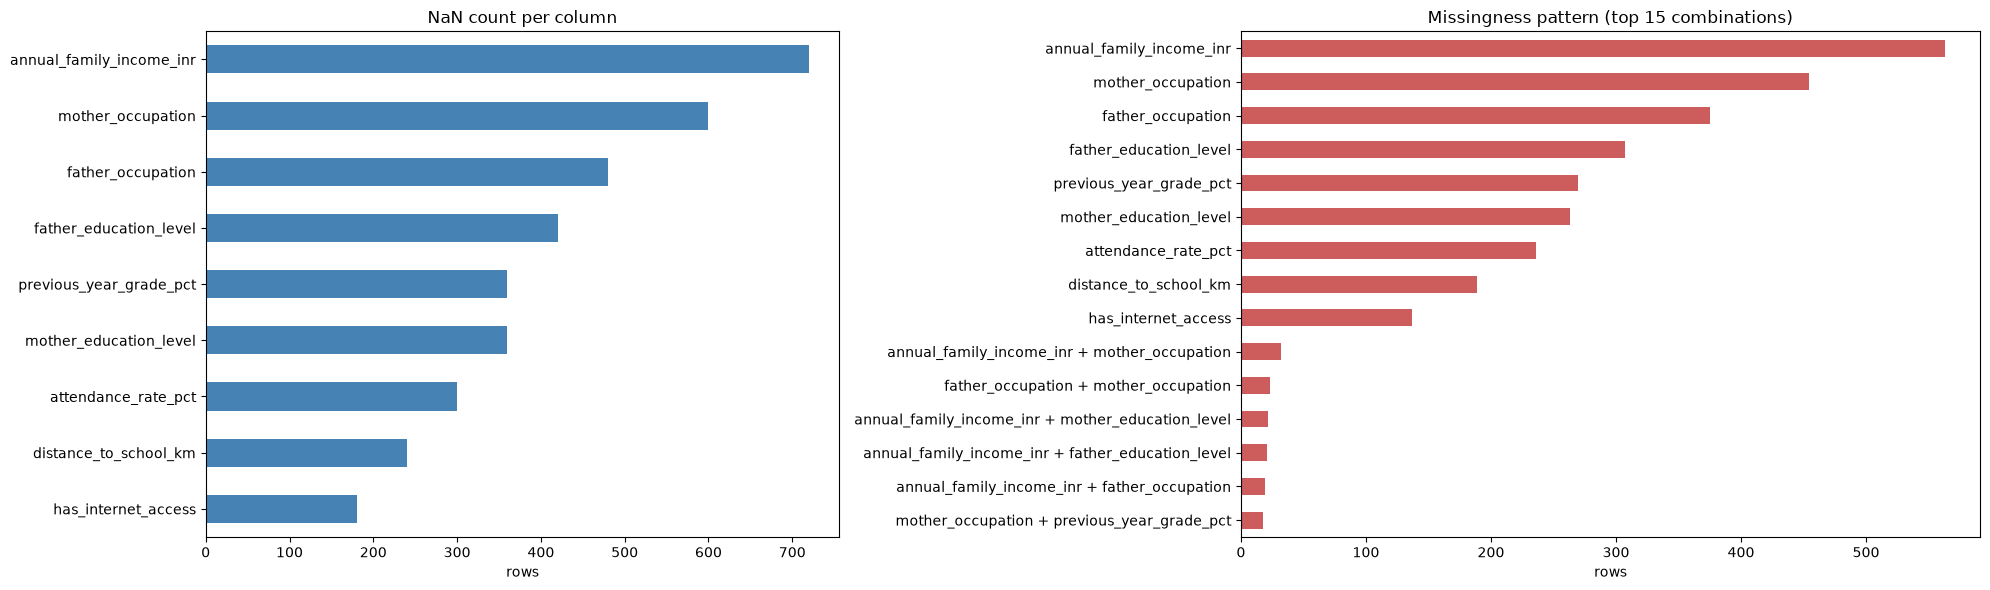

annual_family_income_inr                             563
mother_occupation                                    454
father_occupation                                    375
father_education_level                               307
previous_year_grade_pct                              270
mother_education_level                               263
attendance_rate_pct                                  236
distance_to_school_km                                189
has_internet_access                                  137
annual_family_income_inr + mother_occupation          32
father_occupation + mother_occupation                 23
annual_family_income_inr + mother_education_level     22
annual_family_income_inr + father_education_level     21
annual_family_income_inr + father_occupation          19
mother_occupation + previous_year_grade_pct           18
Name: count, dtype: int64


In [3]:
import matplotlib.pyplot as plt

na = df.isna()
cols = na.columns[na.any()]
na = na[cols]

fig, axes = plt.subplots(1, 2, figsize=(20, 6), gridspec_kw={'width_ratios': [1.2, 1.4]})

# 1. NaN count per column
na.sum().sort_values().plot.barh(ax=axes[0], color='steelblue')
axes[0].set_title('NaN count per column')
axes[0].set_xlabel('rows')

# 2. Missingness pattern: which combinations of columns are missing together
pattern = na[na.any(axis=1)].apply(lambda r: ' + '.join(r.index[r]), axis=1).value_counts()
pattern.head(15).sort_values().plot.barh(ax=axes[1], color='indianred')
axes[1].set_title('Missingness pattern (top 15 combinations)')
axes[1].set_xlabel('rows')

plt.tight_layout()
plt.show()

print(pattern.head(15))

In [4]:
# Check for missing values 
missing_rows = df[df.isna().any(axis=1)]
print("Rows with missing values:")
print(missing_rows) 

# Calculate percentage of missing cells per column 
col_missing_pct = df.isna().mean() * 100

# Filter to only show columns that actually have missing data, sorted highest to lowest
print("\nPercentage of missing values per column:")
print(col_missing_pct[col_missing_pct > 0].sort_values(ascending=False))

# TEMPORARY: drop rows with missing values until a proper imputation strategy is added
rows_before = len(df)
df = df.dropna()
print(f"\n{rows_before} rows -> {len(df)} after dropping rows with missing values")

Rows with missing values:
           academic_year survey_date  age  gender  grade_level  \
student_id                                                       
STU107546      2022-2023      2/5/25   15    Male           10   
STU106506      2022-2023      7/4/25   18    Male           12   
STU103794      2023-2024     20/3/25   16  Female           12   
STU101647      2022-2023     13/3/25   14    Male           10   
STU105006      2021-2022      8/4/25   15    Male            9   
...                  ...         ...  ...     ...          ...   
STU108600      2024-2025      7/3/25   17    Male           11   
STU108332      2024-2025     19/4/25   16  Female           10   
STU106690      2024-2025      6/3/25   13  Female            9   
STU108524      2021-2022      8/4/25   13  Female            9   
STU110137      2023-2024     17/4/25   12  Female            7   

                 school_type residence_type  family_size  num_siblings  \
student_id                               

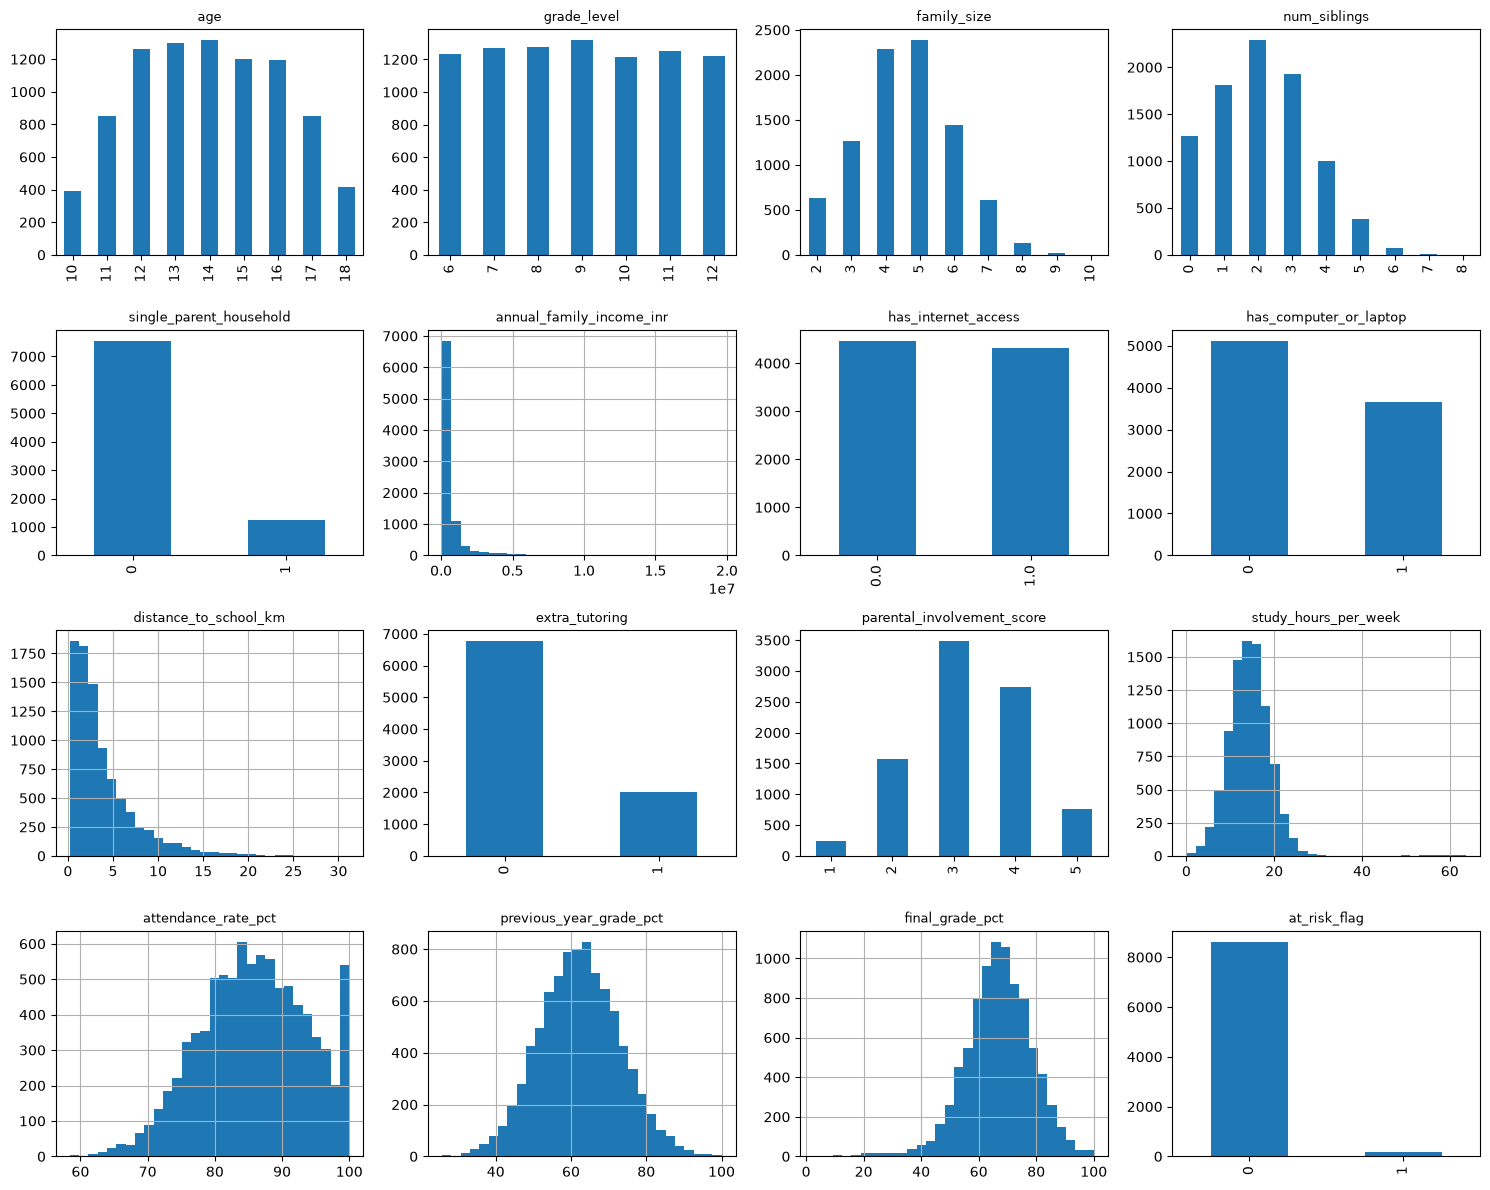

In [5]:
# Visualisation of predictors 

# Columns with only a few integer values get one bar per value
# Default histogram bins cut across the integers and leave gaps
num_cols = df.select_dtypes('number').columns

fig, axes = plt.subplots(4, 4, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    ax = axes[i]
    if df[col].nunique() <= 10:
        df[col].value_counts().sort_index().plot(kind='bar', ax=ax)
        ax.set_xlabel('')
    else:
        df[col].hist(bins=30, ax=ax)
    ax.set_title(col, fontsize=9)

plt.tight_layout()
plt.show()

## Skewed income column: annual_family_income_inr

From the histogram above, we can see that the annual_family_income_inr column is very right-skewed. In the data it ranges from about ₹60,000 to ₹19.6 million, a factor of more than 300. Most families sit near the low end and a few earn far more. On the raw scale, the few very rich families stretch the axis. This creates the problems of the ultra-wealthy outliers having too much influence in linear models. 

In such cases, a log transformation is ideal because algorithms like linear regression, logistics regression, K-means clustering and PCA are highly sensitive to extreme values and perform better when features are normally distributed. As the log is a monotonically increasing function, it naturally squashes massive numbers closer together while preserving the exact rank order of data.

In [6]:
# From the histogram above, heavily skewed income, so log-transform 
print(f"annual_family_income_inr skew: {df['annual_family_income_inr'].skew()}")
df['log_income'] = np.log(df.pop('annual_family_income_inr'))
print(f"log_income skew: {df['log_income'].skew()}")

annual_family_income_inr skew: 4.780808241327416
log_income skew: 0.43251024385922143


## Schema Setup

Based off the variable histograms above, we can deduce which of the columns are discrete/continuous/categorical and we can form the column schema below. 

In [7]:
# Schema Setup 

REGRESSION_TARGET     = 'final_grade_pct'
CLASSIFICATION_TARGET = 'grade_class'

CONTINUOUS_COLS = [
    'distance_to_school_km', 
    'study_hours_per_week', 
    'attendance_rate_pct',          
    'previous_year_grade_pct', 
    'log_income'
]

# Integer-coded, including 0/1 flags and the 1-5 parental involvement score
DISCRETE_COLS = [
    'age', 
    'grade_level', 
    'family_size', 
    'num_siblings', 
    'single_parent_household',
    'has_internet_access', 
    'has_computer_or_laptop', 
    'extra_tutoring',
    'parental_involvement_score'
]

# Text labels
CATEGORICAL_COLS = [
    'academic_year', 
    'gender', 
    'school_type', 
    'residence_type', 
    'family_income_bracket',
    'father_education_level', 
    'mother_education_level', 
    'father_occupation',
    'mother_occupation', 
    'scholarship_status'
]

NUMERIC_COLS = CONTINUOUS_COLS + DISCRETE_COLS
PREDICTOR_COLS = NUMERIC_COLS + CATEGORICAL_COLS

In [8]:
X = df[PREDICTOR_COLS]
print('X:', X.shape)

X: (8785, 24)


## Highly Correlated Predictors 



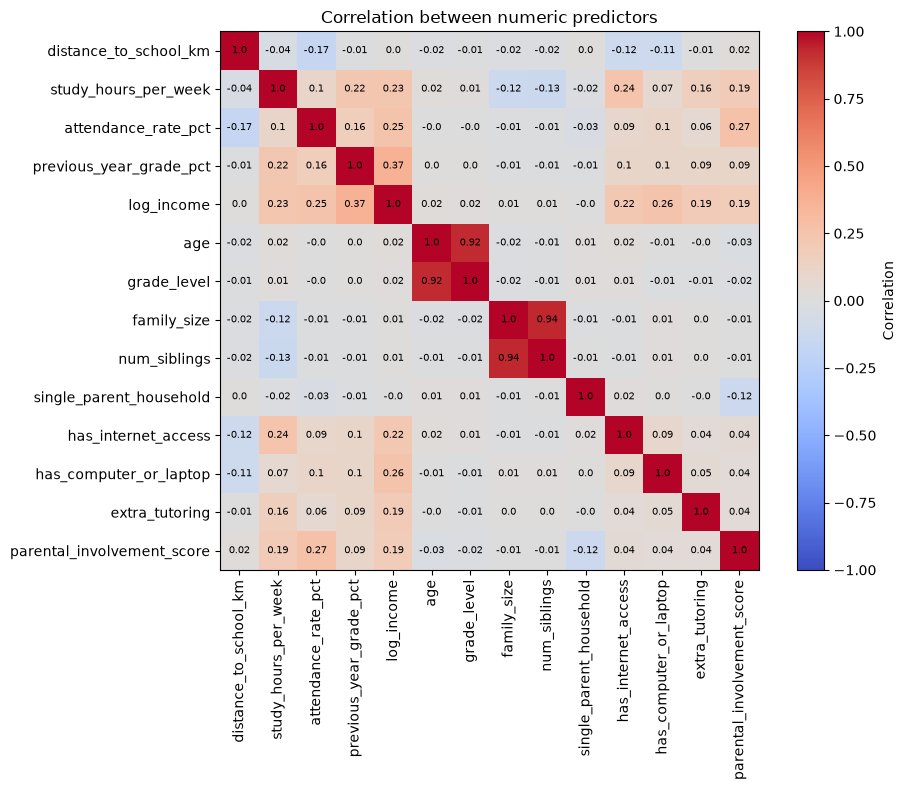

In [9]:
# Correlation heatmap of the numeric predictors
# (categorical columns are text, so they are left out here)
corr = X[NUMERIC_COLS].corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Correlation')
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)

# write the correlation value in each square
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, round(corr.iloc[i, j], 2), ha='center', va='center', fontsize=7)

plt.title('Correlation between numeric predictors')
plt.tight_layout()
plt.show()

From the heatmap, most predictors are only weakly correlated with each other. Two pairs stand out:

- `age` and `grade_level` (r = 0.93): students in the same grade are mostly the same age.
- `family_size` and `num_siblings` (r = 0.94): more siblings means a bigger family.

Keeping both columns of a pair gives the linear models the same information twice, which makes the OLS coefficients unstable. So we drop one column from each pair:

- Keep `grade_level`, drop `age`. Grade level tells us which curriculum the student is in, and age within a grade adds little.
- Keep `family_size`, drop `num_siblings`. Family size also counts parents and other relatives, so it is the more general measure.

Both columns in each pair are almost uncorrelated with `final_grade_pct` (|r| about 0.00 for age/grade level and 0.05 for family size/siblings), so the choice is made on what the variable means rather than on the target. This also avoids using the target before the train/test split.

In [10]:
# Drop one predictor from each highly correlated pair
# age vs grade_level (r = 0.93) -> keep grade_level
# family_size vs num_siblings (r = 0.94) -> keep family_size
DROP_COLS = ['age', 'num_siblings']

DISCRETE_COLS = [c for c in DISCRETE_COLS if c not in DROP_COLS]
NUMERIC_COLS = CONTINUOUS_COLS + DISCRETE_COLS
PREDICTOR_COLS = NUMERIC_COLS + CATEGORICAL_COLS

X                = df[PREDICTOR_COLS]         # Shared predictors
Y_regression     = df[REGRESSION_TARGET]      # Numeric final grade
Y_classification = df[CLASSIFICATION_TARGET]  # Grade band
print('Dropped:', DROP_COLS)
print('X:', X.shape)

Dropped: ['age', 'num_siblings']
X: (8785, 22)


# Inverse-density weighted regression
Compare baseline and density-weighted training on original grade points, with the same 20 paired 85/15 splits and compact grids. Eight models are included; k-NN does not support training sample weights. Classification is omitted.

Weights are proportional to inverse grade density. A Gaussian KDE (Scott bandwidth) is reflected at 0 and 100. Weights are normalized to mean 1, capped at 5, then normalized again; the final maximum may exceed 5. Density and weights are recomputed **inside each training fold**, never from validation/test grades. Both rare low and high grades receive emphasis. No rows are resampled.

Hyperparameters are selected with ordinary validation RMSE. All reported test errors are unweighted. Weight settings are fixed before evaluation; changing them creates a separate checkpoint directory. Four workers run splits in parallel, each using one numerical thread. Run the notebook or `python run_density_notebook.py`; `--smoke` uses a small pilot.


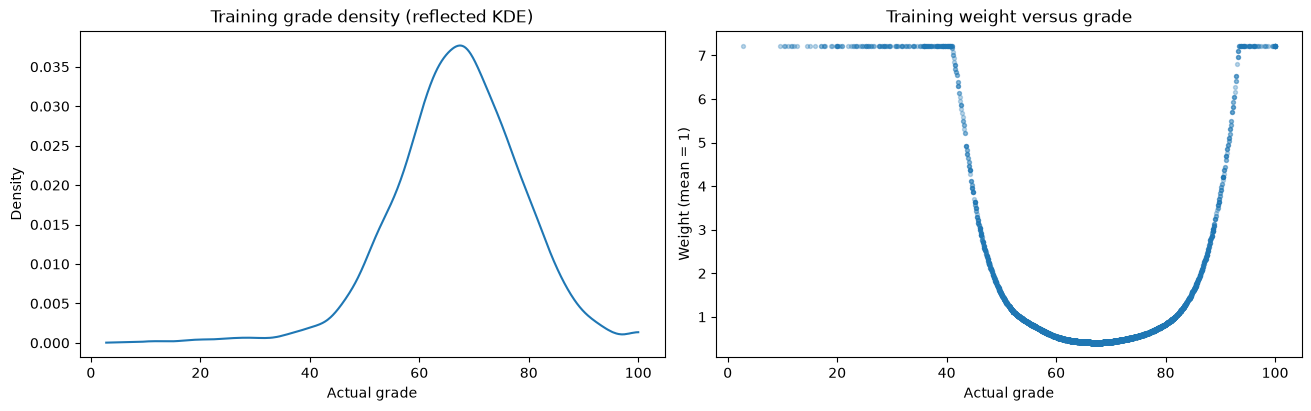

,count,mean_weight,max_weight
grade band,,,
A,134,6.087950,7.227770
B,1639,1.035069,3.775527
C,3871,0.451084,0.551151
D,1686,1.315769,7.227770
F,137,7.227770,7.227770


Weight settings: {'power': 1.0, 'cap': 5.0, 'bandwidth': 'scott'}
Weights affect training only; test metrics remain unweighted.


In [11]:
from IPython.display import display, Markdown
from density_experiment import (run_experiments, NAMES, CONDITIONS, GRIDS, WEIGHT_CONFIG,
                                ONEHOT_COLUMNS, ORDINAL_COLUMNS, density_weights)
from sklearn.model_selection import train_test_split
# Inspect only the first split's training targets; these weights are not reused for CV.
_, _, inspect_y, _ = train_test_split(X, Y_regression, test_size=.15, random_state=0)
w, density = density_weights(inspect_y, **WEIGHT_CONFIG)
order = np.argsort(inspect_y.to_numpy())
fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout='constrained')
axes[0].plot(inspect_y.to_numpy()[order], density[order])
axes[0].set(title='Training grade density (reflected KDE)', xlabel='Actual grade', ylabel='Density')
axes[1].scatter(inspect_y, w, s=8, alpha=.3)
axes[1].set(title='Training weight versus grade', xlabel='Actual grade', ylabel='Weight (mean = 1)')
plt.show()
weight_summary = pd.DataFrame({'grade': inspect_y, 'weight': w, 'grade band': df.loc[inspect_y.index, CLASSIFICATION_TARGET]})
display(weight_summary.groupby('grade band').agg(count=('weight','size'),mean_weight=('weight','mean'),max_weight=('weight','max')))
print('Weight settings:', WEIGHT_CONFIG)
print('Weights affect training only; test metrics remain unweighted.')


In [12]:
import time, platform, importlib.metadata, json
from density_experiment import run_experiments, NAMES, CONDITIONS, GRIDS
REGRESSION_NAMES = NAMES
NUMBER_OF_EXPERIMENTS = 20
N_JOBS = 4
schema = {key: globals()[key] for key in ['CONTINUOUS_COLS','NUMERIC_COLS','PREDICTOR_COLS','ONEHOT_COLUMNS','ORDINAL_COLUMNS']}
start = time.perf_counter()
results, result_directory = run_experiments(X, Y_regression, df[CLASSIFICATION_TARGET], schema,
                                          n_splits=NUMBER_OF_EXPERIMENTS, n_jobs=N_JOBS)
elapsed_seconds = time.perf_counter() - start
regression_predictions = pd.concat([p for r in results for p in r['predictions']], ignore_index=True)
regression_metrics = pd.DataFrame([p for r in results for p in r['metrics']])
regression_timings = pd.DataFrame([p for r in results for p in r['timings']])
for label, frame in [('predictions',regression_predictions),('metrics',regression_metrics),('timings',regression_timings)]:
    frame.to_csv(result_directory / (label+'.csv'),index=False)
versions = {p:importlib.metadata.version(p) for p in ['numpy','pandas','scikit-learn','pygam','joblib']}
manifest = dict(python=platform.python_version(),versions=versions,splits=NUMBER_OF_EXPERIMENTS,workers=N_JOBS,
                elapsed_seconds=elapsed_seconds, grids=GRIDS, target_transform=None, weighting=WEIGHT_CONFIG, evaluation='unweighted', test_size=.15)
(result_directory/'manifest.json').write_text(json.dumps(manifest,indent=2))
print(f'Completed {len(results)} paired splits in {elapsed_seconds/60:.1f} minutes. Results: {result_directory}')
display(manifest)

Split 2: restored checkpoint
Split 3: restored checkpoint
Split 4: restored checkpoint
Split 5: restored checkpoint
Split 6: restored checkpoint
Split 7: restored checkpoint
Split 1: restored checkpoint
Split 8: restored checkpoint
Split 9: restored checkpoint
Split 10: restored checkpoint
Split 11: restored checkpoint
Split 12: restored checkpoint
Split 13: restored checkpoint
Split 14: restored checkpoint
Split 15: restored checkpoint
Split 16: restored checkpoint
Split 17: restored checkpoint
Split 18: restored checkpoint
Split 19: restored checkpoint
Split 20: restored checkpoint
Completed 20 paired splits in 0.0 minutes. Results: density-results/2a1206dce28ef552


{'python': '3.11.18',
 'versions': {'numpy': '2.4.6',
  'pandas': '2.3.3',
  'scikit-learn': '1.7.2',
  'pygam': '0.11.0',
  'joblib': '1.6.0'},
 'splits': 20,
 'workers': 4,
 'elapsed_seconds': 2.1183096670138184,
 'grids': {'Ridge': {'model__alpha': [0.1, 1, 10, 100]},
  'Lasso': {'model__alpha': [0.001, 0.01, 0.1]},
  'GAM': {'model__lam': [0.1, 1, 10, 100]},
  'DT': {'model__max_depth': [3, 6, None], 'model__min_samples_leaf': [5, 20]},
  'RF': {'model__max_features': [0.5, 1.0],
   'model__min_samples_leaf': [5, 20]},
  'GBT': {'model__learning_rate': [0.05, 0.1], 'model__max_depth': [3, 6]}},
 'target_transform': None,
 'weighting': {'power': 1.0, 'cap': 5.0, 'bandwidth': 'scott'},
 'evaluation': 'unweighted',
 'test_size': 0.15}

## Paired comparison
Differences are density weighted minus baseline. Negative error differences favor weighting. Overlapping test splits describe variability rather than independent replications.

RMSE           MAE            R2          F MAE  \
                          mean    std   mean    std   mean    std    mean   
model condition                                                             
DT    Baseline          10.013  0.308  7.449  0.188  0.259  0.026  36.151   
      Density weighted  12.146  0.275  9.544  0.195 -0.092  0.044  31.399   
GAM   Baseline           9.539  0.352  7.000  0.186  0.327  0.030  35.817   
      Density weighted  11.326  0.294  8.748  0.185  0.051  0.039  30.633   
GBT   Baseline           9.628  0.344  7.086  0.188  0.315  0.029  36.078   
      Density weighted  11.202  0.277  8.631  0.177  0.072  0.033  32.376   
Lasso Baseline           9.529  0.349  6.995  0.184  0.329  0.029  35.884   
      Density weighted  10.933  0.299  8.387  0.159  0.116  0.037  30.948   
Naive Baseline          11.635  0.243  8.932  0.183 -0.001  0.001  37.739   
      Density weighted  12.118  0.162  9.453  0.131 -0.086  0.026  34.356   
OLS   Baseline           9.533  0.349  7.000  0.182  0.328  0.030  35.822   
      Density weighted  11.109  0.293  8.532  0.177  0.087  0.037  30.740   
RF    Baseline           9.695  0.332  7.144  0.183  0.305  0.028  36.121   
      Density weighted   9.974  0.332  7.439  0.190  0.264  0.029  34.908   
Ridge Baseline           9.531  0.349  6.998  0.181  0.328  0.029  35.849   
      Density weighted  11.033  0.294  8.473  0.171  0.099  0.036  30.792   

                              F overprediction         
                          std             mean    std  
model condition                                        
DT    Baseline          2.622           36.151  2.622  
      Density weighted  2.982           31.399  2.982  
GAM   Baseline          2.681           35.817  2.681  
      Density weighted  2.951           30.633  2.951  
GBT   Baseline          2.651           36.078  2.651  
      Density weighted  2.968           32.376  2.968  
Lasso Baseline          2.688           35.884  2.688  
      Density weighted  3.166           30.866  3.204  
Naive Baseline          1.698           37.739  1.698  
      Density weighted  1.730           34.356  1.730  
OLS   Baseline          2.703           35.822  2.703  
      Density weighted  3.076           30.614  3.146  
RF    Baseline          2.641           36.121  2.641  
      Density weighted  2.740           34.908  2.740  
Ridge Baseline          2.697           35.849  2.697  
      Density weighted  3.094           30.689  3.153

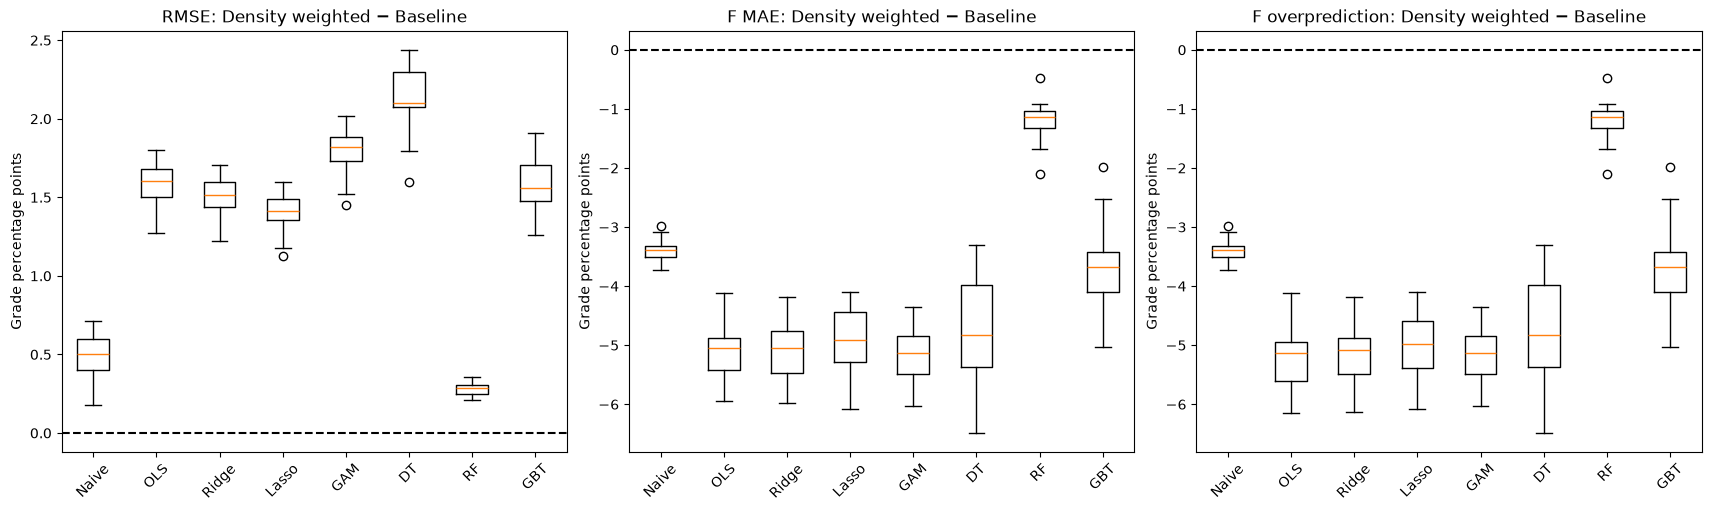

**Observed tradeoff.** OLS: mean RMSE change +1.58, F-band MAE change -5.08 points; RF: mean RMSE change +0.28, F-band MAE change -1.21 points. These are exploratory comparisons across overlapping test splits.

In [13]:
all_predictions = regression_predictions.copy()
all_metrics = regression_metrics.copy()
all_timings = regression_timings.copy()
all_predictions['absolute error'] = (all_predictions.predicted-all_predictions.actual).abs()
all_predictions['overprediction'] = all_predictions.predicted-all_predictions.actual
f_metrics = (all_predictions[all_predictions['grade band'].eq('F')]
    .groupby(['experiment','condition','model']).agg(**{'F MAE':('absolute error','mean'),
          'F overprediction':('overprediction','mean'), 'F support':('actual','size')}).reset_index())
comparison = all_metrics.merge(f_metrics, on=['experiment','condition','model'], how='left')
metrics_to_compare = ['RMSE','MAE','R2','F MAE','F overprediction']
display(comparison.groupby(['model','condition'])[metrics_to_compare].agg(['mean','std']).round(3))
fig, axes = plt.subplots(1,3,figsize=(17,5),layout='constrained')
paired_deltas = {}
for ax, metric in zip(axes,['RMSE','F MAE','F overprediction']):
    pairs = comparison.pivot(index=['experiment','model'],columns='condition',values=metric)
    delta = (pairs['Density weighted']-pairs['Baseline']).unstack('model').reindex(columns=NAMES)
    paired_deltas[metric] = delta
    ax.boxplot([delta[m].dropna() for m in NAMES],tick_labels=NAMES)
    ax.axhline(0,color='black',ls='--'); ax.tick_params(axis='x',rotation=45)
    ax.set(title=metric+': Density weighted − Baseline',ylabel='Grade percentage points')
plt.show()
comparison.to_csv(result_directory/'comparison.csv',index=False)
display(Markdown('**Observed tradeoff.** '+ '; '.join(
    f"{m}: mean RMSE change {paired_deltas['RMSE'][m].mean():+.2f}, F-band MAE change {paired_deltas['F MAE'][m].mean():+.2f} points"
    for m in ['OLS','RF'])+'. These are exploratory comparisons across overlapping test splits.'))
# Verify identical held-out students and finite predictions.
for (_, _), group in all_predictions.groupby(['experiment','model']):
    a = group[group.condition.eq('Baseline')].set_index('student_id')
    b = group[group.condition.eq('Density weighted')].set_index('student_id')
    assert a.index.equals(b.index) and np.array_equal(a.actual, b.actual)
assert np.isfinite(all_predictions.predicted).all()


In [14]:
# Generate findings from the current run, including smoke runs.
means = comparison.groupby(['model','condition'])[['RMSE','F MAE']].mean()
rmse_delta = paired_deltas['RMSE'].mean()
f_delta = paired_deltas['F MAE'].mean()
lines = [f"### Findings from {NUMBER_OF_EXPERIMENTS} paired splits", "",
         f"Density weighting reduced mean overall RMSE for {int((rmse_delta < 0).sum())} of {len(NAMES)} models and F-band MAE for {int((f_delta < 0).sum())} of {len(NAMES)} models.", "",
         "| Model | Baseline RMSE | Weighted RMSE | Baseline F MAE | Weighted F MAE |",
         "|---|---:|---:|---:|---:|"]
for name in NAMES:
    base, transformed = means.loc[(name,'Baseline')], means.loc[(name,'Density weighted')]
    lines.append(f"| {name} | {base['RMSE']:.3f} | {transformed['RMSE']:.3f} | {base['F MAE']:.3f} | {transformed['F MAE']:.3f} |")
lines += ["", "Errors are grade percentage points. Overlapping splits are exploratory comparisons, not independent replications. Check the size of changes and low-grade overprediction alongside overall accuracy. This baseline uses the same compact grids as the logit experiment and can differ from the original pilot-tuned notebook."]
display(Markdown('\n'.join(lines)))


### Findings from 20 paired splits

Density weighting reduced mean overall RMSE for 0 of 8 models and F-band MAE for 8 of 8 models.

| Model | Baseline RMSE | Weighted RMSE | Baseline F MAE | Weighted F MAE |
|---|---:|---:|---:|---:|
| Naive | 11.635 | 12.118 | 37.739 | 34.356 |
| OLS | 9.533 | 11.109 | 35.822 | 30.740 |
| Ridge | 9.531 | 11.033 | 35.849 | 30.792 |
| Lasso | 9.529 | 10.933 | 35.884 | 30.948 |
| GAM | 9.539 | 11.326 | 35.817 | 30.633 |
| DT | 10.013 | 12.146 | 36.151 | 31.399 |
| RF | 9.695 | 9.974 | 36.121 | 34.908 |
| GBT | 9.628 | 11.202 | 36.078 | 32.376 |

Errors are grade percentage points. Overlapping splits are exploratory comparisons, not independent replications. Check the size of changes and low-grade overprediction alongside overall accuracy. This baseline uses the same compact grids as the logit experiment and can differ from the original pilot-tuned notebook.

grade band                   A       B      C       D       F
model condition                                              
DT    Baseline          16.401   9.150  4.804   8.809  36.151
      Density weighted  15.027  12.771  9.051   5.442  31.399
GAM   Baseline          14.861   8.469  4.573   8.168  35.817
      Density weighted  13.334  11.412  7.999   5.808  30.633
GBT   Baseline          15.421   8.738  4.490   8.404  36.078
      Density weighted  14.548  11.157  7.824   5.730  32.376
Lasso Baseline          15.425   8.485  4.522   8.198  35.884
      Density weighted  14.429  10.679  7.400   6.178  30.948
Naive Baseline          26.884  13.353  3.545  13.079  37.739
      Density weighted  30.266  16.736  4.619   9.697  34.356
OLS   Baseline          15.078   8.414  4.606   8.134  35.822
      Density weighted  14.163  10.713  7.564   6.447  30.740
RF    Baseline          16.268   8.784  4.543   8.429  36.121
      Density weighted  14.637   9.420  5.532   7.116  34.908
Ridge Baseline          15.173   8.438  4.577   8.153  35.849
      Density weighted  14.245  10.700  7.498   6.339  30.792

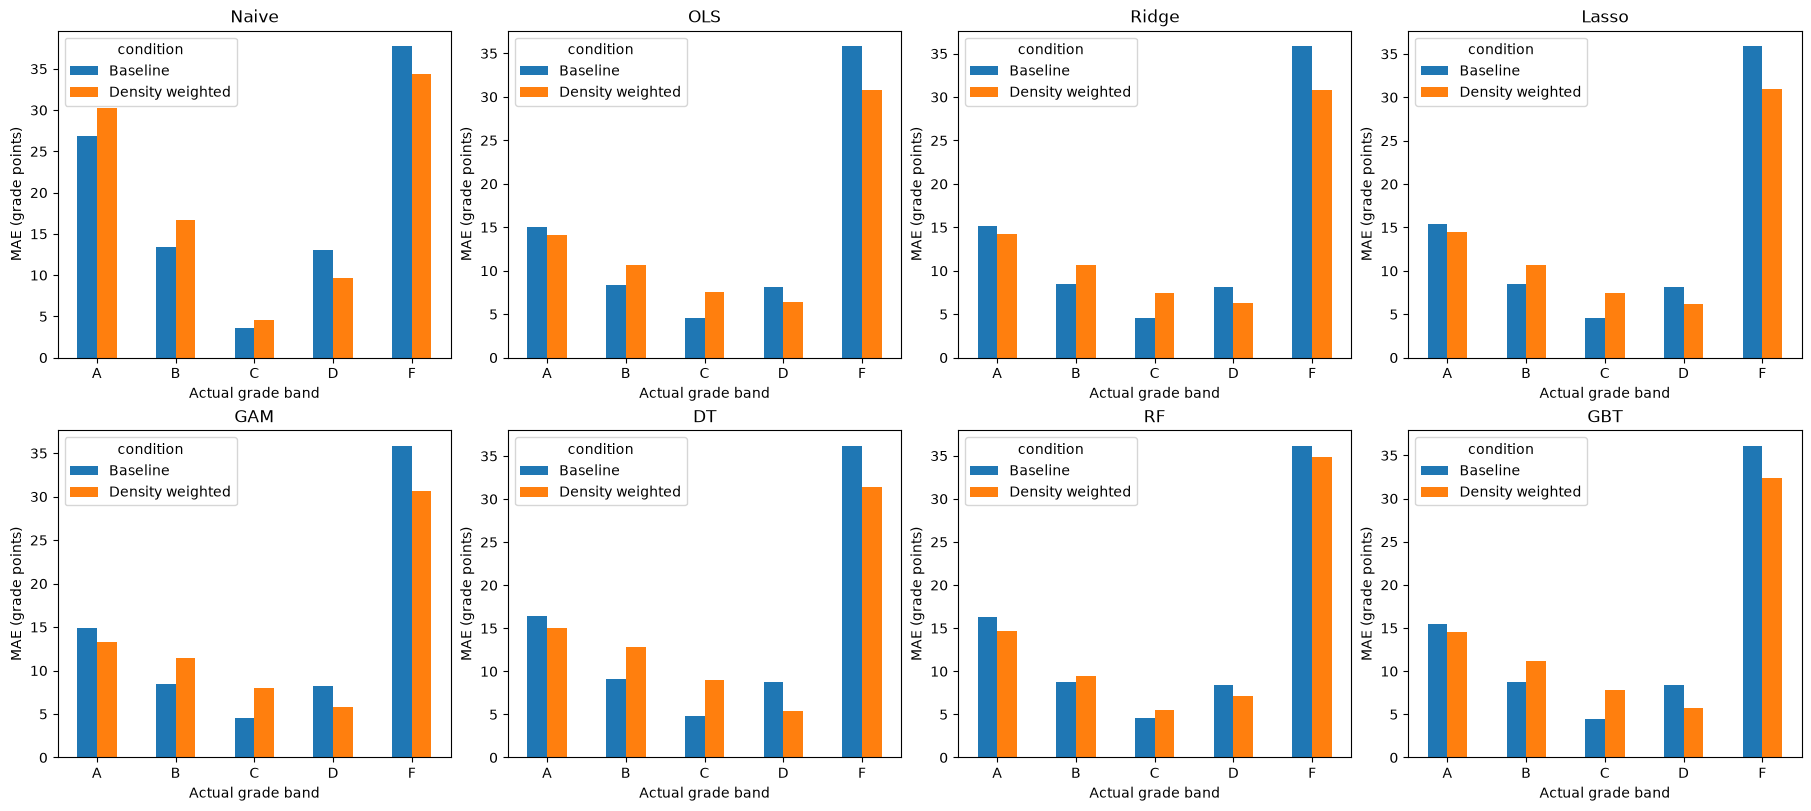

In [15]:
# Grade-band errors: all test observations receive equal weight.
band_errors = (all_predictions.groupby(['experiment','model','condition','grade band'])['absolute error']
               .mean().rename('MAE').reset_index())
band_summary = band_errors.groupby(['model','condition','grade band']).MAE.mean().unstack('grade band')
display(band_summary.round(3))
band_errors.to_csv(result_directory/'grade-band-errors.csv', index=False)
fig, axes = plt.subplots(2, 4, figsize=(18, 8), layout='constrained')
for ax, name in zip(axes.flat, NAMES):
    summary = band_errors[band_errors.model.eq(name)].groupby(['grade band','condition']).MAE.mean().unstack('condition')
    summary.reindex(columns=CONDITIONS).plot.bar(ax=ax, rot=0)
    ax.set(title=name, xlabel='Actual grade band', ylabel='MAE (grade points)')
plt.show()


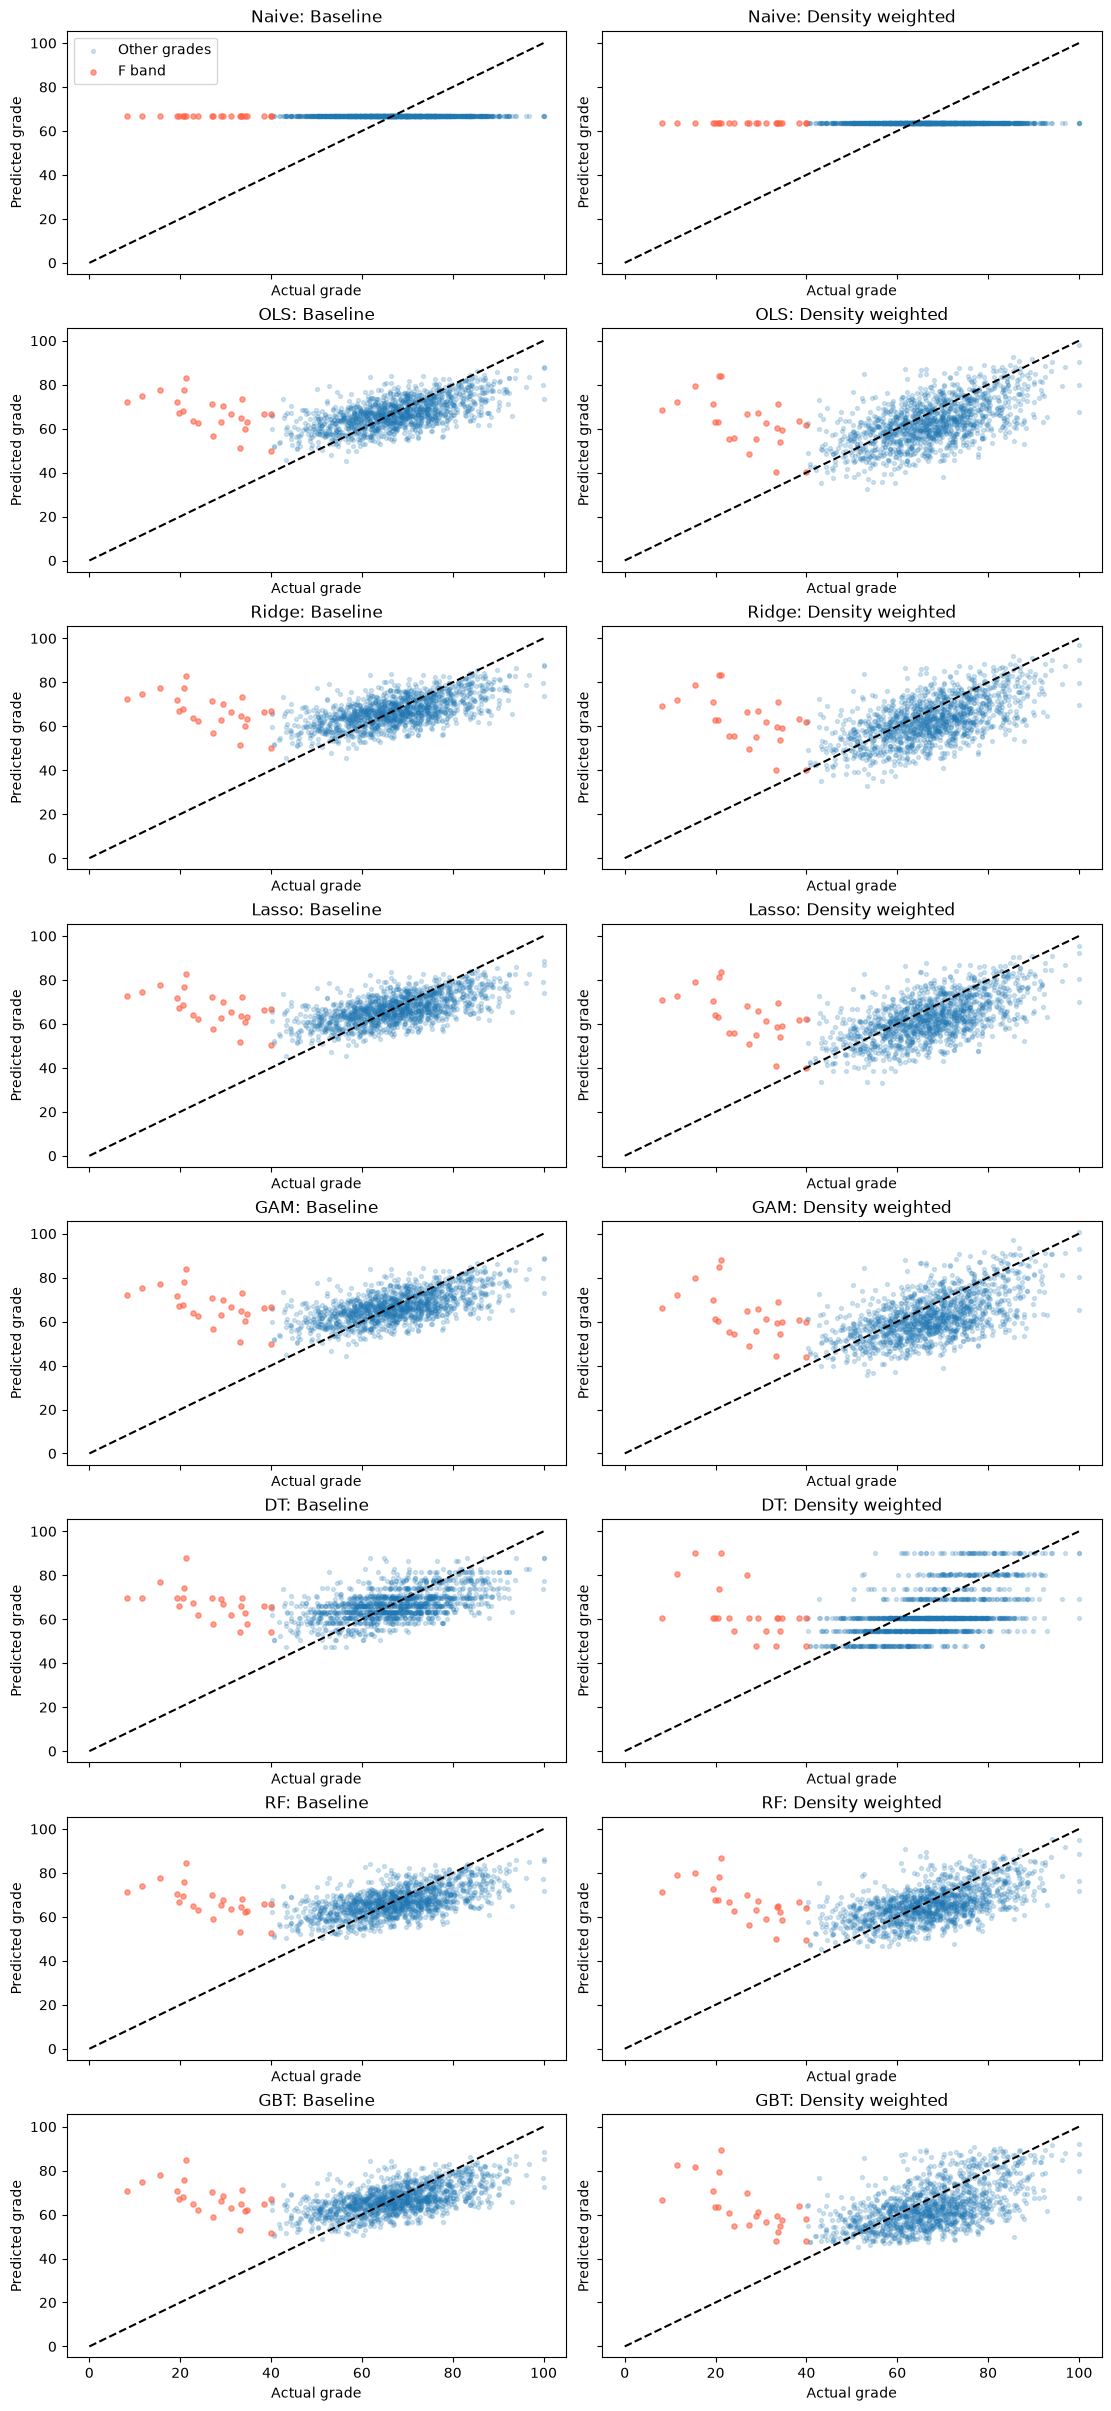

In [17]:
# Predicted versus actual: first held-out split, with shared axes.
fig, axes = plt.subplots(len(NAMES), 2, figsize=(11, 3*len(NAMES)), layout='constrained', sharex=True, sharey=True)
for row, name in enumerate(NAMES):
    for col, condition in enumerate(CONDITIONS):
        p = all_predictions[(all_predictions.experiment == 0) & all_predictions.model.eq(name) & all_predictions.condition.eq(condition)]
        low = p['grade band'].eq('F')
        ax = axes[row, col]
        ax.scatter(p.loc[~low,'actual'], p.loc[~low,'predicted'], s=8, alpha=.2, label='Other grades')
        ax.scatter(p.loc[low,'actual'], p.loc[low,'predicted'], s=14, alpha=.6, color='tomato', label='F band')
        ax.plot([0,100], [0,100], '--', color='black')
        ax.set(title=f'{name}: {condition}', xlabel='Actual grade', ylabel='Predicted grade')
axes[0,0].legend()
plt.show()
